# FD001: từ dữ liệu cảm biến đến một mẫu dự đoán RUL

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Một dòng C-MAPSS ghi trạng thái của một động cơ tại một cycle (chu kỳ vận hành). Để dự đoán RUL (Remaining Useful Life, số cycle còn lại đến khi hỏng), pipeline cần biến lịch sử
cảm biến thành các mẫu có cùng cấu trúc và ghép mỗi mẫu train với đúng nhãn.

Notebook theo dõi **động cơ train 1 tại cycle 100** qua các bước: đọc raw, tổ chức observations, tạo nhãn,
lưu dữ liệu, tính đặc trưng cửa sổ rồi dựng X/y. Sau đó chạy lại bằng Spark và trên HDFS để kiểm tra kết quả.
Mọi bảng được tính và ghi mới trong lần chạy này; nhãn test được giữ riêng.

<details>
<summary>Môi trường để chạy toàn bộ notebook</summary>

Dùng kernel Python của `.venv`, có các dependency của project và extra `etl`. Java và Docker Desktop cần sẵn sàng.
Hadoop dùng Compose project `cmapss-notebook00`, cổng NameNode 9871 và YARN 8089.
Mỗi lần chạy tạo thư mục `outputs/notebook00/run-*/`; các container được giữ chạy để xem dữ liệu trên HDFS.

</details>

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data/raw"
from cmapss.presentation import COLORS, apply_plot_style, style_figure
import matplotlib.pyplot as plt

apply_plot_style()


## 1. Một dòng raw chứa gì?

FD001 có ba file. `train_FD001.txt` và `test_FD001.txt` chứa observations, mỗi dòng có 26 trường:
`engine_id`, `cycle`, 3 operational settings và 21 sensor. `RUL_FD001.txt` chứa một nhãn cho mỗi động cơ test.

Train ghi lịch sử đến khi động cơ hỏng. Test chỉ ghi một đoạn đầu của lịch sử, nên cycle cuối của test
không phải thời điểm hỏng. Notebook đọc hai file observations và để riêng nhãn test.
[Nguồn dữ liệu NASA](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data).

In [2]:
from cmapss.data.readers import read_observations

train = read_observations(RAW / "train_FD001.txt", split="train")
test = read_observations(RAW / "test_FD001.txt", split="test")

columns = ["split", "engine_id", "cycle", "setting_1", "sensor_11"]
train.loc[:, columns].head(3)

,split,engine_id,cycle,setting_1,sensor_11
0,train,1,1,-0.0007,47.47
1,train,1,2,0.0019,47.49
2,train,1,3,-0.0043,47.27


Ba dòng trên thuộc cùng một động cơ, ở các cycle liên tiếp. Sensor là phép đo tại từng cycle,
chưa phải đặc trưng của một khoảng thời gian. Reader gán tên cột, chuyển kiểu và kiểm tra dữ liệu;
cột `split` được thêm để ghi nguồn train/test.

In [3]:
pd.DataFrame({
    "split": ["train", "test"],
    "observations": [len(train), len(test)],
    "engines": [train.engine_id.nunique(), test.engine_id.nunique()],
    "columns_after_split": [train.shape[1], test.shape[1]],
})

,split,observations,engines,columns_after_split
0,train,20631,100,27
1,test,13096,100,27


Train có 20.631 dòng, test có 13.096 dòng; mỗi tập có 100 động cơ. Sau khi thêm `split`, mỗi bảng có 27 cột.
ID và cycle có kiểu số nguyên; settings và sensors có kiểu số thực.
Trước khi biến đổi, kiểm tra thêm checksum để xác nhận hai file đúng với bản dữ liệu đã ghi nhận.

In [4]:
import hashlib
from cmapss.data.acquire import EXPECTED_SHA256

raw_hashes = {
    name: hashlib.sha256((RAW / name).read_bytes()).hexdigest()
    for name in ("train_FD001.txt", "test_FD001.txt")
}
for name, digest in raw_hashes.items():
    if digest != EXPECTED_SHA256[name]:
        raise ValueError(f"Checksum không khớp: {name}")
print("Hai file observations khớp SHA-256 đã ghi nhận.")

Hai file observations khớp SHA-256 đã ghi nhận.


## 2. Nối train/test và xác định khóa

Hai file có cùng schema nên được nối theo chiều dòng. Đây là union, không phải ghép train và test thành
một lịch sử động cơ. Cột `split` phải đi cùng `engine_id` và `cycle` trong khóa.

In [5]:
from cmapss.data.contracts import KEY
from cmapss.data.validation import validate_observations

observations = (pd.concat([train, test], ignore_index=True)
                .sort_values(list(KEY), kind="mergesort").reset_index(drop=True))
validate_observations(observations)
observations.query("engine_id == 1 and cycle == 1")[columns].reset_index(drop=True)

,split,engine_id,cycle,setting_1,sensor_11
0,test,1,1,0.0023,47.20
1,train,1,1,-0.0007,47.47


Cả hai dòng đều có `engine_id = 1`, `cycle = 1`, nhưng là hai động cơ khác nhau.
Khóa `(engine_id, cycle)` sẽ trùng giữa train và test; khóa đầy đủ là `(split, engine_id, cycle)`.
Bảng nối có 33.727 dòng. Mỗi dòng vẫn đại diện cho một động cơ tại một cycle.

## 3. Tạo nhãn RUL cho train

Vì lịch sử train kết thúc khi hỏng, RUL được tính theo từng động cơ:

$$\mathrm{RUL}_{i,t}=T_i-t,$$

trong đó $T_i$ là cycle cuối của động cơ $i$. Động cơ train 1 có $T_1=192$;
tại cycle 100, nhãn là $192-100=92$ cycle. Nhãn này được lưu riêng để ghép với features sau.

In [6]:
from cmapss.data.targets import make_train_targets

targets = make_train_targets(train)
engine1 = train.query("engine_id == 1").copy()
targets.query("engine_id == 1 and cycle in [1, 100, 192]").reset_index(drop=True)

,split,engine_id,cycle,rul
0,train,1,1,191
1,train,1,100,92
2,train,1,192,0


RUL giảm từ 191 xuống 0 trên động cơ này. Công thức dùng cycle cuối để tạo **nhãn**, không đưa cycle cuối
vào features. Với test, lịch sử đã bị cắt nên không thể suy nhãn bằng cách lấy cycle cuối trừ cycle hiện tại.

## 4. Lưu observations và nhãn để dùng tiếp

Observations và targets được lưu thành Silver Parquet: dữ liệu đã kiểm tra, còn giữ từng cycle. Một nhánh khác tổng hợp lịch sử thành
`engine_summary`: mỗi dòng là một động cơ, với số cycle, cycle đầu và cycle cuối.
Bảng tổng hợp thuộc lớp Gold, phục vụ truy vấn theo động cơ. Bảng này và targets có thêm bản SQLite để truy vấn bằng SQL.

Ví dụ dưới đây cho thấy động cơ train 1 có 192 cycle, còn động cơ test 1 mới quan sát được 31 cycle.

In [7]:
from cmapss.etl.pandas_pipeline import build_engine_summary

engine_summary = build_engine_summary(observations)
engine_summary.query("engine_id == 1").reset_index(drop=True)

,split,engine_id,n_cycles,first_cycle,last_cycle
0,test,1,31,1,31
1,train,1,192,1,192


Observations có 33.727 dòng theo cycle; `engine_summary` có 200 dòng theo động cơ.
Đây là hai mức tổng hợp khác nhau. Features theo thời gian sẽ được tính từ observations,
vì bảng tổng hợp động cơ không còn các giá trị sensor tại từng cycle.

In [8]:
import tempfile
from cmapss.etl.pandas_pipeline import PandasETLResult, write_pandas_artifacts

output_root = ROOT / "outputs/notebook00"
output_root.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
etl = PandasETLResult(observations=observations, train_targets=targets,
                     engine_summary=engine_summary, input_sha256=raw_hashes,
                     dataset_id="FD001", raw_dir=str(RAW.resolve()))
etl_info = write_pandas_artifacts(etl, RUN_DIR / "etl")
OBS_PATH = RUN_DIR / "etl/silver/observations.parquet"
TARGET_PATH = RUN_DIR / "etl/silver/train_targets.parquet"
SUMMARY_PATH = RUN_DIR / "etl/gold/engine_summary.parquet"

Các bước tiếp theo đọc từ những file vừa ghi. Kiểm tra round-trip xác nhận việc lưu/đọc không làm đổi dữ liệu.

In [9]:
silver_obs = pd.read_parquet(OBS_PATH)
silver_targets = pd.read_parquet(TARGET_PATH)
gold_summary = pd.read_parquet(SUMMARY_PATH)
pd.testing.assert_frame_equal(observations, silver_obs)
pd.testing.assert_frame_equal(targets, silver_targets)
pd.testing.assert_frame_equal(engine_summary, gold_summary)
print("Ba bảng Parquet đọc lại khớp dữ liệu trước khi ghi.")

Ba bảng Parquet đọc lại khớp dữ liệu trước khi ghi.


### Truy vấn cùng mẫu bằng SQLite

Join bảng tổng hợp với targets theo `split` và `engine_id` để lấy nhãn tại cycle 100.
Ở quan hệ này, một dòng động cơ ghép với nhiều dòng target theo cycle.

In [10]:
from contextlib import closing
import sqlite3

SQLITE_PATH = RUN_DIR / "etl/gold/etl.sqlite"
with closing(sqlite3.connect(SQLITE_PATH)) as connection:
    sql_example = pd.read_sql("""
        SELECT s.split, s.engine_id, s.last_cycle, t.cycle, t.rul
        FROM engine_summary s
        JOIN train_targets t ON s.split = t.split AND s.engine_id = t.engine_id
        WHERE s.split = 'train' AND s.engine_id = 1 AND t.cycle = 100
    """, connection)
assert sql_example.rul.item() == 92
sql_example

,split,engine_id,last_cycle,cycle,rul
0,train,1,192,100,92


## 5. Từ 30 cycle thành một dòng features

Một phép đo đơn lẻ chưa thể hiện xu hướng. Tại cycle 100, pipeline lấy **30 cycle từ 71 đến 100** của
cùng động cơ. Các cycle sau 100 chưa xảy ra tại thời điểm dự đoán nên không được dùng.

Đường xám dưới đây là toàn bộ lịch sử để đối chiếu. Đoạn xanh là phần dữ liệu được phép dùng cho mẫu này.

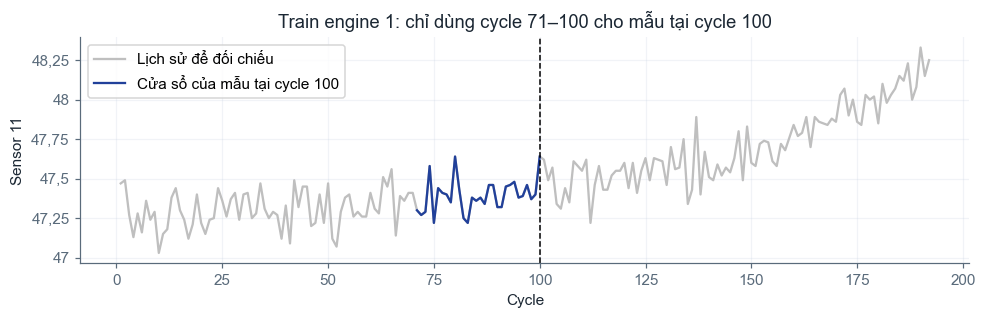

In [11]:
import matplotlib.pyplot as plt

window = engine1.loc[engine1.cycle.between(71, 100)]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(engine1.cycle, engine1.sensor_11, color="0.75", label="Lịch sử để đối chiếu")
ax.plot(window.cycle, window.sensor_11, color=COLORS["blue"], label="Cửa sổ của mẫu tại cycle 100")
ax.axvline(100, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Cycle", ylabel="Sensor 11", title="Động cơ train 1: chỉ dùng cycle 71–100 cho mẫu tại cycle 100")
ax.legend(loc="upper left")
fig.tight_layout()
(RUN_DIR / "figures").mkdir()
style_figure(fig)
fig.savefig(RUN_DIR / "figures/window_engine1.png", dpi=150)
style_figure(plt.gcf())
plt.show()

Với mỗi sensor, cửa sổ được rút thành 6 giá trị: `last` (phép đo cuối), `mean` (trung bình),
`std` (độ lệch chuẩn mẫu, ddof = 1), `min`, `max` và `slope` (hệ số góc hồi quy theo cycle).
21 sensor tạo **126 features**. Operational settings không thuộc bộ features này.

Hàm dưới đây đọc Silver Parquet vừa tạo và tính cửa sổ riêng cho từng `(split, engine_id)`.

In [12]:
from cmapss.features.rolling import run_rolling_feature_pipeline, write_rolling_feature_artifacts

feature_result = run_rolling_feature_pipeline(OBS_PATH, window_cycles=30)
write_rolling_feature_artifacts(feature_result, RUN_DIR / "features")
FEATURE_PATH = RUN_DIR / "features/gold/rolling_features.parquet"
features = pd.read_parquet(FEATURE_PATH)
sample = features.query("split == 'train' and engine_id == 1 and cycle == 100").iloc[0]
sample.filter(like="sensor_11_").rename("giá trị").to_frame()

,giá trị
sensor_11__last,47.64
sensor_11__mean,47.395
sensor_11__std,0.105332
sensor_11__min,47.22
sensor_11__max,47.64
sensor_11__slope,0.003669


Ví dụ, `sensor_11__mean = 47.395` là trung bình của 30 phép đo trong đoạn xanh.
Giá trị `slope` dương cho biết đường hồi quy trong cửa sổ có chiều tăng; nó không phải nhãn RUL.

Chỉ tạo mẫu khi đủ 30 cycle. Vì vậy, mỗi động cơ mất 29 dòng đầu:
train còn $20.631 - 100 \times 29 = 17.731$ mẫu; test còn $13.096 - 100 \times 29 = 10.196$ mẫu.

In [13]:
assert len(window) == 30
assert np.isclose(sample.sensor_11__mean, window.sensor_11.mean())
assert np.isclose(sample.sensor_11__std, window.sensor_11.std(ddof=1))
pd.DataFrame({
    "observations": silver_obs.groupby("split").size(),
    "feature_rows": features.groupby("split").size(),
    "first_feature_cycle": features.groupby("split").cycle.min(),
})

,observations,feature_rows,first_feature_cycle
split,,,
test,13096,10196,30
train,20631,17731,30


## 6. Ghép features với nhãn: X và y

Mỗi dòng features được gắn RUL theo **đủ ba cột khóa**. Ví dụ, dòng
`(train, 1, 100)` phải nhận nhãn 92 đã tính ở bước 3.
Hàm của project kiểm tra quan hệ một–một và báo lỗi nếu thiếu nhãn.

In [14]:
from cmapss.modeling.baseline.dataset import prepare_modeling_dataset
from cmapss.modeling.contracts import MODELING_FEATURE_COLUMNS

train_dataset = prepare_modeling_dataset(features, silver_targets)
X = train_dataset.loc[:, list(MODELING_FEATURE_COLUMNS)]
y = train_dataset["rul"]
example_columns = list(KEY) + ["sensor_11__last", "sensor_11__mean", "rul"]
train_dataset.query("engine_id == 1 and cycle == 100")[example_columns].reset_index(drop=True)

,split,engine_id,cycle,sensor_11__last,sensor_11__mean,rul
0,train,1,100,47.64,47.395,92


X gồm 17.731 dòng và 126 cột sensor features; y có 17.731 nhãn. Ba cột khóa phục vụ truy vết,
không được đưa vào X. Đến đây, dữ liệu đã sẵn sàng cho bước chia train/validation theo động cơ.

Với test, chỉ lấy cửa sổ tại cycle cuối đã quan sát của mỗi động cơ: 100 dòng cho 100 dự đoán.
Ở notebook này, test chưa được ghép với nhãn và chưa dùng để chấm mô hình.

In [15]:
test_endpoints = (features.loc[features.split.eq("test")]
                  .sort_values(list(KEY)).groupby("engine_id", sort=True).tail(1))
assert X.shape == (17731, 126) and y.shape == (17731,)
assert len(test_endpoints) == test_endpoints.engine_id.nunique() == 100
assert train_dataset.query("engine_id == 1 and cycle == 100").rul.item() == 92

(RUN_DIR / "model_inputs").mkdir()
train_dataset.to_parquet(RUN_DIR / "model_inputs/train_dataset.parquet", index=False)
test_endpoints.to_parquet(RUN_DIR / "model_inputs/test_endpoints.parquet", index=False)
pd.DataFrame({
    "input": ["X train", "y train", "X test endpoints"],
    "shape": [X.shape, y.shape, (len(test_endpoints), X.shape[1])],
})

,input,shape
0,X train,"(17731, 126)"
1,y train,"(17731,)"
2,X test endpoints,"(100, 126)"


## 7. Chạy cùng phép biến đổi bằng Spark

Pandas ở trên giúp quan sát từng bước. Bây giờ Spark đọc lại raw, tạo observations, targets,
engine summary và rolling features. Cần so sánh cả khóa lẫn giá trị, vì số dòng bằng nhau chưa chứng minh
hai cách triển khai cho cùng kết quả.

Phiên Spark này chạy `local[1]` trên máy hiện tại. Nó kiểm tra sự thống nhất của logic; không đo khả năng
xử lý của một cluster nhiều máy.

In [16]:
import os
from cmapss.etl.spark_pipeline import create_spark_session, run_spark_etl
from cmapss.etl.rolling_spark import build_spark_rolling_features

bundled_java = ROOT / "tmp/java-runtime/jdk-17.0.20.1+1-jre"
if not os.environ.get("JAVA_HOME") and bundled_java.is_dir():
    os.environ["JAVA_HOME"] = str(bundled_java)
os.environ["PYSPARK_PYTHON"] = sys.executable

In [17]:
with create_spark_session("notebook00-data-walkthrough") as spark:
    spark.sparkContext.setLogLevel("ERROR")
    spark_etl = run_spark_etl(RAW, dataset_id="FD001", spark=spark)
    spark_obs, spark_targets, spark_summary = spark_etl.to_pandas()
    spark_features = (build_spark_rolling_features(spark_etl.observations, window_cycles=30)
                      .orderBy(*KEY).toPandas())

In [18]:
from cmapss.etl.parity import compare_frames

comparisons = [
    ("observations", silver_obs, spark_obs, KEY),
    ("train_targets", silver_targets, spark_targets, KEY),
    ("engine_summary", gold_summary, spark_summary, ("split", "engine_id")),
    ("rolling_features", features, spark_features, KEY),
]
parity = []
for name, reference, candidate, keys in comparisons:
    result = compare_frames(reference, candidate, name=name, key_columns=keys,
                            numeric_columns=[c for c in reference if c not in keys],
                            rtol=1e-7, atol=1e-7)
    parity.append(result.as_dict())
pd.DataFrame(parity)[["name", "rows", "status", "max_abs_diff"]]

,name,rows,status,max_abs_diff
0,observations,33727,passed,0.000000e+00
1,train_targets,20631,passed,0.000000e+00
2,engine_summary,200,passed,0.000000e+00
3,rolling_features,27927,passed,1.259419e-10


`max_abs_diff` là sai lệch tuyệt đối lớn nhất. Các bảng ETL phải khớp; rolling features có thể
lệch rất nhỏ do thứ tự tính số thực. Phép kiểm tra dùng `rtol = atol = 1e-7` và sẽ dừng notebook nếu vượt ngưỡng.

## 8. Đưa raw lên HDFS và chạy job đọc dữ liệu từ đó

Parquet ở các bước trước nằm trên ổ đĩa máy hiện tại. Bước này tạo một bản dữ liệu trên HDFS (hệ thống
lưu trữ phân tán của Hadoop), rồi thực hiện hai job:

- MapReduce chạy trên YARN, đọc raw để tính số cycle của từng động cơ.
- Spark đọc raw từ HDFS, ghi Silver Parquet lên HDFS rồi tạo cùng bảng tổng hợp động cơ.

Cả hai kết quả được đối chiếu với `engine_summary` vừa tính ở bước 4. Bước này cần Docker Desktop đang chạy
và có thể mất vài phút khi phải tải image lần đầu.

In [19]:
from cmapss.hdfs.stage import run_stage

os.environ["CMAPSS_NAMENODE_PORT"] = "9871"
os.environ["CMAPSS_YARN_PORT"] = "8089"
hdfs_base = f"/cmapss/notebook00/{RUN_DIR.name}"
hdfs_summary = run_stage(
    RAW, SUMMARY_PATH, RUN_DIR / "hdfs", keep_running=True,
    hdfs_base=hdfs_base, project="cmapss-notebook00",
)
pd.DataFrame({
    "MapReduce / Pandas": hdfs_summary["mapreduce_vs_pandas"],
    "Spark HDFS / Pandas": hdfs_summary["spark_vs_pandas"],
}).T

,rows_reference,rows_candidate,mismatched_cells,exact_match
MapReduce / Pandas,200,200,0,True
Spark HDFS / Pandas,200,200,0,True


Mỗi job phải trả về 200 dòng động cơ và `exact_match = True`.
Silver trên HDFS chứa 33.727 observations; bảng tổng hợp không thay thế lịch sử cảm biến.

Có thể xem file trong [NameNode UI](http://localhost:9871/explorer.html) và job tại
[YARN UI](http://localhost:8089/cluster). Dữ liệu lần chạy này nằm dưới đường dẫn được in bên dưới.
Cấu hình hiện tại có **một DataNode**, replication = 1; Spark đọc HDFS bằng `local[2]`.
Đây là cách chạy thực tế của bài tập trên một máy, chưa chứng minh khả năng mở rộng hay chịu lỗi nhiều node.

In [20]:
assert hdfs_summary["spark_silver_rows"] == len(silver_obs)
assert hdfs_summary["spark_silver_null_values"] == 0
print(f"HDFS: {hdfs_base}")
display(pd.DataFrame({
    "layer": list(hdfs_summary["hdfs_paths"]),
    "relative_path": [p.removeprefix(hdfs_base + "/") for p in hdfs_summary["hdfs_paths"].values()],
}))

HDFS: /cmapss/notebook00/run-cc0j7g58


,layer,relative_path
0,bronze,bronze/fd001
1,silver,silver/observations
2,gold_mapreduce,gold/mapreduce_engine_summary
3,gold_spark,gold/spark_engine_summary


## 9. Kết quả của lần chạy

Mẫu `(train, 1, 100)` bắt đầu từ 30 dòng cảm biến tại cycle 71–100, trở thành 126 features
và nhận nhãn RUL = 92. Toàn bộ train có 17.731 mẫu cùng cấu trúc.
File train giữ thêm ba cột khóa và cột `rul`; khi huấn luyện, chỉ lấy 126 cột của X.

Các file được tạo trong thư mục riêng của lần chạy. Lưu một bản tóm tắt và kiểm tra raw
không bị thay đổi trước khi kết thúc.

In [21]:
import json

assert all(hashlib.sha256((RAW / name).read_bytes()).hexdigest() == digest
           for name, digest in raw_hashes.items())
run_summary = {
    "author": "Phan Nguyễn Mai Phương", "student_id": "25002711", "status": "passed",
    "raw_unchanged": True, "test_labels_read": False, "raw_sha256": raw_hashes,
    "rows": {"observations": len(silver_obs), "train_targets": len(silver_targets),
             "engine_summary": len(gold_summary), "rolling_features": len(features),
             "train_dataset": len(train_dataset), "test_endpoints": len(test_endpoints)},
    "spark_parity": parity, "hdfs": hdfs_summary,
}
(RUN_DIR / "run_summary.json").write_text(json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Kết quả lần chạy: {RUN_DIR.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook00\run-cc0j7g58


Notebook dừng ở dữ liệu đầu vào mô hình. Notebook 01 phân tích sensor; các notebook modeling thực hiện
huấn luyện và đánh giá theo giao thức riêng. Chưa có chỉ số dự đoán nào được suy ra từ các phép kiểm tra dữ liệu ở đây.